<a href="https://colab.research.google.com/github/Arturo215/Metodos-numericos-/blob/main/NWmp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#El método de Newton-Raphson

Es un algoritmo iterativo que utiliza la recta tangente de una curva para encontrar aproximaciones sucesivas a sus raíces. Dada una función f(x) y una estimación inicial $p_0$, el método calcula el siguiente punto evaluando la intersección de la recta tangente con el eje horizontal mediante la fórmula:

#$p_{n+1} = p_n - \frac{f(p_n)}{f'(p_n)}$


Para la función establecida en tu problema, $f(x) = \cos(x) - x$, es necesario calcular su derivada, la cual resulta en $f'(x) = -\sin(x) - 1$. Al sustituir estos elementos en la fórmula general, la iteración específica para este ejercicio se define algebraicamente como:$p_{n+1} = p_n + \frac{\cos(p_n) - p_n}{\sin(p_n) + 1}$

<>:60: SyntaxWarning: invalid escape sequence '\c'
<>:60: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_723/4005595235.py:60: SyntaxWarning: invalid escape sequence '\c'
  plt.title('Búsqueda de raíz para $f(x) = \cos(x) - x$', fontsize=14)


Tabla de Iteraciones - Método de Newton
Iter  | p_n        | f(p_n)       | f(p_n)       | Error     
-----------------------------------------------------------------
1     | 0.785398   | -0.078291    | -1.707107    | 0.045862  
2     | 0.739536   | -0.000755    | -1.673945    | 0.000451  
3     | 0.739085   | -0.000000    | -1.673612    | 0.000000  
-----------------------------------------------------------------
Raíz aproximada final: 0.739085



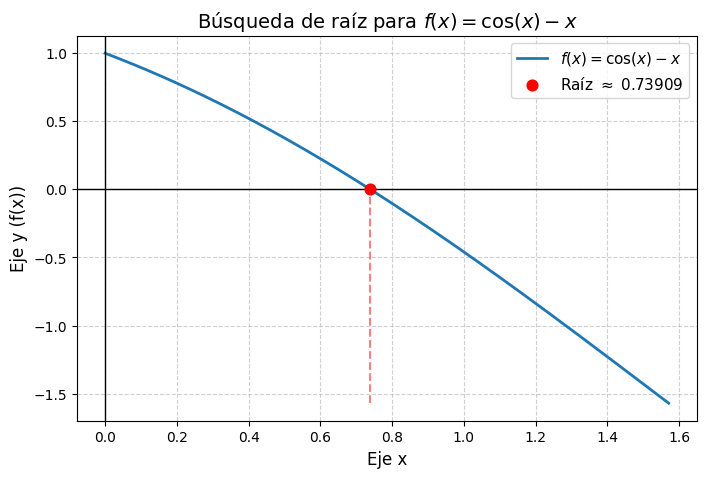

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Definición de la función y su derivada
def f(x):
    return np.cos(x) - x

def df(x):
    return -np.sin(x) - 1

def newton_raphson(p0, tol):
    print("Tabla de Iteraciones - Método de Newton")
    print(f"{'Iter':<5} | {'p_n':<10} | {'f(p_n)':<12} | {'f''(p_n)':<12} | {'Error':<10}")
    print("-" * 65)

    p_actual = p0
    for n in range(1, 20):
        f_val = f(p_actual)
        df_val = df(p_actual)

        # Cálculo iterativo mediante la fórmula de Newton
        p_nuevo = p_actual - (f_val / df_val)
        error = abs(p_nuevo - p_actual)

        print(f"{n:<5} | {p_actual:<10.6f} | {f_val:<12.6f} | {df_val:<12.6f} | {error:<10.6f}")

        if error < tol:
            return p_nuevo

        p_actual = p_nuevo

    return p_actual

# 2. Ejecución del método numérico
# Se utiliza el punto medio del intervalo [0, pi/2] como estimación inicial
p0 = np.pi / 4
tolerancia = 1e-6
raiz = newton_raphson(p0, tolerancia)

print("-" * 65)
print(f"Raíz aproximada final: {raiz:.6f}\n")

# 3. Generación de la gráfica
# Evaluamos la función a lo largo del intervalo [0, pi/2]
x_vals = np.linspace(0, np.pi/2, 200)
y_vals = f(x_vals)

plt.figure(figsize=(8, 5))
plt.plot(x_vals, y_vals, label=r'$f(x) = \cos(x) - x$', color='#1f77b4', linewidth=2)

# Ejes de referencia
plt.axhline(y=0, color='black', linestyle='-', linewidth=1)
plt.axvline(x=0, color='black', linestyle='-', linewidth=1)

# Punto de la raíz encontrada
plt.scatter(raiz, 0, color='red', zorder=5, s=60, label=f'Raíz $\\approx$ {raiz:.5f}')
# Línea punteada marcando la raíz
plt.vlines(x=raiz, ymin=min(y_vals), ymax=0, color='red', linestyle='--', alpha=0.5)

plt.title('Búsqueda de raíz para $f(x) = \cos(x) - x$', fontsize=14)
plt.xlabel('Eje x', fontsize=12)
plt.ylabel('Eje y (f(x))', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)

# Despliegue de la figura
plt.show()